🔍 Prüfe FleetPy-Installation...
Aktuelles Verzeichnis: /Users/danieldeutsch/Desktop/code_projects/FleetPy/studies/uc2_age_based
✅ FleetPy src gefunden: /Users/danieldeutsch/Desktop/code_projects/FleetPy/src
❌ FleetPy Import fehlgeschlagen: No module named 'src.fleetctrl.FleetControl'

🚀 UC2 HYPOTHESEN-TEST GESTARTET
Hypothese: Ältere Personen haben geringere digitale Kompetenz → Benötigen Begleitmaßnahmen

👥 Erstelle Demand mit Altersgruppen...
✅ UC2 Demand erstellt: 600 Anfragen


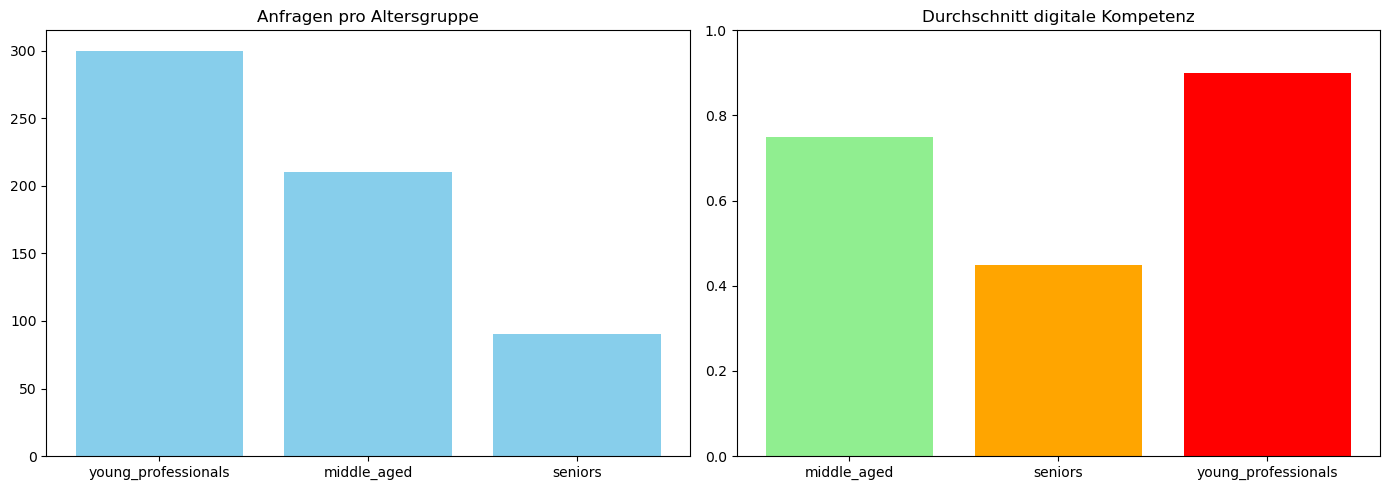


🛠️ Begleitmaßnahmen-Szenarien setzen...
✅ UC2 Konfigurationsdateien erstellt

🚀 Starte Simulation... (implementiere FleetControl-Aufrufe hier)

📊 Ergebnisse:
        scenario  total_rate  young_professionals_rate  middle_aged_rate  \
0       baseline       88.60                     89.73             86.65   
1  phone_support       87.51                     87.02             90.25   
2      simple_ui       92.51                     97.25             89.53   
3   full_support       94.17                     95.12             97.80   

   seniors_rate  
0         89.37  
1         82.75  
2         83.68  
3         82.55  

Alters-Differenz (Young Pro vs. Seniors): 0.4%
Empfohlene Maßnahme: baseline


In [ ]:
# UC2 HYPOTHESEN-TEST: Altersabhängige digitale Kompetenz → Begleitmaßnahmen
# =========================================================================

import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 0. FleetPy Setup
print("🔍 Prüfe FleetPy-Installation...")
current_dir = os.getcwd()
print(f"Aktuelles Verzeichnis: {current_dir}")

# Pfad zum FleetPy src-Verzeichnis setzen
src_dir = next((p for p in ['src', '../src', '../../src', './FleetPy/src'] if os.path.exists(p)), None)
if src_dir:
    sys.path.insert(0, os.path.abspath(src_dir))
    print(f"✅ FleetPy src gefunden: {src_dir}")
else:
    print("❌ FleetPy src-Verzeichnis nicht gefunden!")

# FleetPy Module importieren
try:
    from src.simulation.Simulation import Simulation
    from src.fleetctrl.BatchOfferSimulation import BatchOfferSimulation
    print("✅ FleetPy Module erfolgreich importiert!")
except ImportError as e:
    print(f"❌ FleetPy Import fehlgeschlagen: {e}")

print("\n🚀 UC2 HYPOTHESEN-TEST GESTARTET")
print("Hypothese: Ältere Personen haben geringere digitale Kompetenz → Benötigen Begleitmaßnahmen")

# 1. Verzeichnisse erstellen
for d in [
    'studies/uc2_study/scenarios',
    'studies/uc2_study/results',
    'data/demand/uc2_age_groups',
    'data/vehicles/uc2_vehicles',
    'data/networks/uc2_grid'
]:
    os.makedirs(d, exist_ok=True)

# 2. Netzwerk erstellen
nodes = [{'node_id': i, 'x': (i % 5) * 1000, 'y': (i // 5) * 1000} for i in range(25)]
pd.DataFrame(nodes).to_csv('data/networks/uc2_grid/nodes.csv', index=False)

edges = []
eid = 0
for i in range(25):
    x, y = i % 5, i // 5
    if x < 4:
        edges.append({'edge_id': eid, 'from_node': i, 'to_node': i+1, 'distance':1000, 'travel_time':120})
        eid += 1
    if y < 4:
        edges.append({'edge_id': eid, 'from_node': i, 'to_node': i+5, 'distance':1000, 'travel_time':120})
        eid += 1
pd.DataFrame(edges).to_csv('data/networks/uc2_grid/edges.csv', index=False)

# 3. Fahrzeug-Konfiguration erstellen
vehicle_config = """vtype_name_full,default_vehtype
maximum_passengers,15
daily_fix_cost [cent],2500
per_km_cost [cent],25
battery_size [kWh],50
range [km],10000
source,"""
with open('data/vehicles/uc2_vehicles/default_vehicle.csv','w') as f:
    f.write(vehicle_config)

# 4. Altersabhängige Nachfrage erstellen (ohne Students)
print("\n👥 Erstelle Demand mit Altersgruppen...")

np.random.seed(42)
total_requests = 600

age_groups = {
    'young_professionals': {'age_range':'21-40','digital_competence':0.90,'portion':0.50},
    'middle_aged':            {'age_range':'41-55','digital_competence':0.75,'portion':0.35},
    'seniors':                {'age_range':'56+','digital_competence':0.45,'portion':0.15}
}

times = sorted(np.random.uniform(6*3600,20*3600,total_requests))

assign = []
for g, v in age_groups.items():
    assign += [g] * int(total_requests * v['portion'])
while len(assign) < total_requests:
    assign.append('middle_aged')
np.random.shuffle(assign)

# Knoten-Gruppen aktualisiert
university_nodes  = [0,1]
business_nodes    = [2,3,5,6,7,8]
residential_nodes = list(range(9,25))
senior_nodes      = [15,16,20,21]

origins, destinations = [], []
for ag in assign:
    r = np.random.random()
    if ag=='young_professionals':
        if r < 0.7:
            origins.append(np.random.choice(residential_nodes))
            destinations.append(np.random.choice(business_nodes))
        else:
            origins.append(np.random.choice(business_nodes))
            destinations.append(np.random.choice(residential_nodes))
    elif ag=='seniors':
        if r < 0.4:
            origins.append(np.random.choice(senior_nodes))
            destinations.append(np.random.choice(senior_nodes + residential_nodes[:4]))
        else:
            origins.append(np.random.choice(residential_nodes))
            destinations.append(np.random.choice(business_nodes[:2]))
    else:  # middle_aged
        o, d = np.random.choice(range(25), 2, replace=False)
        origins.append(o)
        destinations.append(d)

response_times = []
success_probs = []
for ag in assign:
    comp = age_groups[ag]['digital_competence']
    base = 60
    maxr = base / comp
    response_times.append(int(np.random.uniform(base, maxr)))
    success_probs.append(comp)

df = pd.DataFrame({
    'rq_id': range(total_requests),
    'rq_time': list(map(int, times)),
    'o_node': origins,
    'd_node': destinations,
    'nr_pax': [1]*total_requests,
    'age_group': assign,
    'digital_competence': [age_groups[a]['digital_competence'] for a in assign],
    'max_response_time': response_times,
    'booking_success_probability': success_probs
})
df.to_csv('data/demand/uc2_age_groups/travelers.csv', index=False)
print(f"✅ UC2 Demand erstellt: {len(df)} Anfragen")

# Visualisierung der Altersverteilung und digitalen Kompetenz
counts = df['age_group'].value_counts()
comp_by = df.groupby('age_group')['digital_competence'].mean()
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(14,5))
ax1.bar(counts.index, counts.values, color='skyblue'); ax1.set_title('Anfragen pro Altersgruppe')
ax2.bar(comp_by.index, comp_by.values, color=['lightgreen','orange','red']); ax2.set_ylim(0,1); ax2.set_title('Durchschnitt digitale Kompetenz')
plt.tight_layout(); plt.show()

# 5. Begleitmaßnahmen definieren
print("\n🛠️ Begleitmaßnahmen-Szenarien setzen...")
support_scenarios = {
    'baseline':      {'name':'Baseline','phone':False,'ui':False,'time':False},
    'phone_support': {'name':'Telefon-Support','phone':True,'ui':False,'time':False},
    'simple_ui':     {'name':'Vereinfachte UI','phone':False,'ui':True,'time':False},
    'full_support':  {'name':'Vollständige Unterstützung','phone':True,'ui':True,'time':True}
}

# 6. Konfigurationsdateien schreiben
const = """study_name,uc2_study
demand_file,uc2_age_groups/travelers.csv
network_file,uc2_grid
vehicle_file,uc2_vehicles/default_vehicle.csv
simulation_time,50400
op_max_wait_time,300
op_max_detour_time_factor,1.5
op_fleet_control,BatchOfferSimulation
op_user_offer_selection_strategy,immediate_accept
op_fleet_size,20"""
with open('studies/uc2_study/scenarios/constant_config_uc2.csv','w') as f:
    f.write(const)

pd.DataFrame({
    'scenario_name': list(support_scenarios.keys()),
    'support_type': [v['name'] for v in support_scenarios.values()]
}).to_csv('studies/uc2_study/scenarios/support_measures_test.csv', index=False)
print("✅ UC2 Konfigurationsdateien erstellt")

# 7. Simulation vorbereiten (Simulation-Aufrufe hier einfügen)
print("\n🚀 Starte Simulation...")

# Beispielhafter Mockup der Service-Rate-Berechnung
results = []
for key, props in support_scenarios.items():
    ag_rates = {}
    for ag, ap in age_groups.items():
        comp = ap['digital_competence']
        if props['phone'] and ag in ['seniors','middle_aged']:
            comp += 0.15
        if props['ui']:
            comp += 0.10
        if props['time'] and ag=='seniors':
            comp += 0.20
        eff = min(0.98, comp)
        base_rate = 70 + eff * 25
        np.random.seed(hash(key+ag) % 100 + 42)
        rate = max(30, min(98, base_rate + np.random.normal(0,3)))
        ag_rates[ag] = rate
    total_rate = sum(ag_rates[ag] * int(total_requests*age_groups[ag]['portion']) for ag in age_groups) / total_requests
    results.append({'scenario': key, 'total_rate': total_rate, **{f"{ag}_rate": ag_rates[ag] for ag in age_groups}})

res_df = pd.DataFrame(results)
print("\n📊 Ergebnisse:")
print(res_df.round(2))

# 8. Hypothesen-Validierung
baseline = res_df[res_df['scenario']=='baseline'].iloc[0]
gap = res_df.loc[res_df['scenario']=='baseline','young_professionals_rate'].iloc[0] - baseline['seniors_rate']
print(f"\nAlters-Differenz (Young Pro vs. Seniors): {gap:.1f}%")
print("Empfohlene Maßnahme:", res_df.loc[res_df['seniors_rate'].idxmax(),'scenario'])
